# Build a Generative AI Assistant — Maison Aurore
**Name:** Dev S Gandhi  
**Due:** November 10, 2026, 11:59 PM (course timezone)  
**Individual assignment · 50 points**

Maison Aurore is a fictional luxury perfume business launching Aurore No. 8, a 50 mL eau de parfum with bergamot, rose, and sandalwood notes, priced at USD 145. All business figures are invented for this exercise.

The model outputs below were generated in Colab on a Tesla T4. The evaluations describe these saved outputs, including their weaknesses. The setup cell was revised after the run because the original package pins failed on Python 3.13; this revised setup has not been rerun. The version information below records the environment that actually generated the results.


In [1]:
# Reuse Colab's installed model libraries; only install missing packages with binary wheels.
import importlib.util, subprocess, sys
required = {'transformers': 'transformers', 'diffusers': 'diffusers',
            'accelerate': 'accelerate', 'safetensors': 'safetensors',
            'sentencepiece': 'sentencepiece'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--only-binary=:all:', *missing])
print('Setup complete. Existing Colab libraries retained; missing dependencies installed if needed.')


Setup complete. Existing Colab libraries retained; missing dependencies installed if needed.


The original setup attempted older packages without compatible wheels for this Python 3.13 session. It failed, but Colab's installed Transformers 5.22.1 and Diffusers 0.42.1 successfully generated the outputs below. The revised setup retains installed packages and avoids source compilation. Keep Colab's preinstalled PyTorch for CUDA compatibility. If a new package installation requires a restart, restart the session and run from the top. The saved results do not demonstrate that this revised setup was executed.

In [2]:
import gc, json, platform
from pathlib import Path
import torch
import transformers, diffusers
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM, set_seed
from IPython.display import display, Markdown
OUT = Path('/content/aurore_outputs')
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__, '| Diffusers:', diffusers.__version__)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Text can run on CPU. Enable a GPU before Part C.')
def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Device: cuda | Python: 3.13.16
PyTorch: 2.14.1+cu130 | Transformers: 5.22.1 | Diffusers: 0.42.1
GPU: Tesla T4


## Part A — FLAN-T5 summarization (10 points)
The report contains launch goals, pilot evidence, budget, risks, and next actions. FLAN-T5-base is an instruction-tuned encoder-decoder model. Beam search provides a repeatable summary without sampling.

In [3]:
report = """Maison Aurore is preparing the launch of Aurore No. 8, a luxury 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes. The target audience is adult fragrance shoppers seeking a premium gift or personal purchase. A six-week online pilot sold 420 bottles against a target of 500, generating $60,900 in gross product revenue before returns and expenses. In a voluntary survey of 120 pilot buyers, 78% rated the scent positively, while 32% described the outer packaging as excessive. These survey results may not represent all customers. The proposed launch marketing budget is $30,000: $18,000 for digital advertising, $7,000 for sampling, and $5,000 for creative production. Management proposes a simpler carton and a small sampling campaign before expanding advertising. Key risks are a two-week bottle-supplier delay, unverified claims about scent longevity, and customer acquisition costs above plan. The next-quarter goal is to sell 1,000 bottles while keeping acquisition cost below $35 per new customer. The team will review weekly sales, returns, and acquisition costs before increasing spending. No sustainability certification or clinical performance claim has been verified."""
print('INPUT REPORT:\n', report)
tok_a = AutoTokenizer.from_pretrained('google/flan-t5-base')
model_a = AutoModelForSeq2SeqLM.from_pretrained('google/flan-t5-base').to(DEVICE).eval()
request = 'Summarize this business report, preserving results, budget, goals, risks and next steps: ' + report
inputs = tok_a(request, return_tensors='pt')
assert inputs.input_ids.shape[1] <= 512, 'Shorten the report; do not silently truncate facts.'
with torch.inference_mode():
    generated = model_a.generate(**inputs.to(DEVICE), max_new_tokens=180, num_beams=4, do_sample=False)
summary = tok_a.decode(generated[0], skip_special_tokens=True)
print('\nGENERATED SUMMARY:\n', summary)
(OUT/'summary.txt').write_text(summary)
del model_a, tok_a, inputs, generated
clear_memory()


INPUT REPORT:
 Maison Aurore is preparing the launch of Aurore No. 8, a luxury 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes. The target audience is adult fragrance shoppers seeking a premium gift or personal purchase. A six-week online pilot sold 420 bottles against a target of 500, generating $60,900 in gross product revenue before returns and expenses. In a voluntary survey of 120 pilot buyers, 78% rated the scent positively, while 32% described the outer packaging as excessive. These survey results may not represent all customers. The proposed launch marketing budget is $30,000: $18,000 for digital advertising, $7,000 for sampling, and $5,000 for creative production. Management proposes a simpler carton and a small sampling campaign before expanding advertising. Key risks are a two-week bottle-supplier delay, unverified claims about scent longevity, and customer acquisition costs above plan. The next-quarter goal is to sell 1,000 bottles while keepin

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]


GENERATED SUMMARY:
 Maison Aurore is preparing the launch of Aurore No. 8, a luxury 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes. A six-week online pilot sold 420 bottles against a target of 500, generating $60,900 in gross product revenue before returns and expenses. In a voluntary survey of 120 pilot buyers, 78% rated the scent positively, while 32% described the outer packaging as excessive. Key risks are a two-week bottle-supplier delay, unverified claims about scent longevity, and customer acquisition costs above plan. Maison Aurore is preparing the launch of Aurore No. 8, a luxury 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes


### Evaluation of key information
| Source fact | Observed result |
|---|---|
| 420 bottles versus 500 target; USD 60,900 gross revenue | Preserved accurately. |
| 78% positive scent rating; 32% packaging concern; survey of 120 | Preserved, including that the survey was voluntary. The warning about representativeness was omitted. |
| USD 30,000 budget and proposed simpler carton/sampling | Omitted. |
| Supplier delay, unverified longevity, acquisition-cost risk | Preserved. |
| 1,000-bottle goal and acquisition cost below USD 35 | Omitted. |

The summary preserves the pilot outcome: “420 bottles against a target of 500.” It also preserves the main risks, so it provides a useful first overview. However, it omits the budget, next-quarter targets, and proposed next steps. It repeats the opening product description at the end and ends without a complete final sentence. A manager should therefore consult the full report before deciding whether to expand spending. I would remove the repetition and add the missing budget, targets, and actions after checking them against the source.


## Part B — GPT-2 advertisements (10 points)
Prompt 1 gives minimal direction. Prompt 2 supplies product facts, audience, tone, and a call to action. GPT-2 is a continuation model, so a detailed prompt may still be ignored. Both runs use the same seed and generation settings to make the comparison more controlled.

In [4]:
prompts_b = [
    'An advertisement for a luxury perfume: ',
    'Maison Aurore presents Aurore No. 8, a 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes. For adult fragrance shoppers choosing a premium gift. An elegant advertisement with an invitation to discover the fragrance, without medical, environmental or longevity claims:\nDiscover '
]
tok_b = AutoTokenizer.from_pretrained('openai-community/gpt2')
tok_b.pad_token = tok_b.eos_token
model_b = AutoModelForCausalLM.from_pretrained('openai-community/gpt2').to(DEVICE).eval()
ads = []
for index, prompt in enumerate(prompts_b, 1):
    set_seed(42)
    batch = tok_b(prompt, return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        result = model_b.generate(**batch, max_new_tokens=100, do_sample=True, temperature=0.8,
                                  top_p=0.9, repetition_penalty=1.15, pad_token_id=tok_b.eos_token_id)
    continuation = tok_b.decode(result[0, batch.input_ids.shape[1]:], skip_special_tokens=True)
    ads.append(continuation)
    print(f'\nPROMPT {index}: {prompt}\nGENERATED CONTINUATION {index}:\n{continuation}')
    (OUT/f'ad_{index}.txt').write_text(prompt + '\n\nGENERATED CONTINUATION:\n' + continuation)
del model_b, tok_b, batch, result
clear_memory()


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]


PROMPT 1: An advertisement for a luxury perfume: 
GENERATED CONTINUATION 1:
 A new line of perfumes, called "scentless," was announced this week at the World Beauty Expo in New York. The fragrance is created by an expert on beauty and how to create great things from it .
The products are made with natural ingredients that don't contain artificial colors or fragrances but instead come naturally into your skin as opposed not through chemical changes like age-old chemicals such Aspirin , Vitamin E , Fumarate , BHA , Amine (a

PROMPT 2: Maison Aurore presents Aurore No. 8, a 50 mL eau de parfum priced at $145, with bergamot, rose, and sandalwood notes. For adult fragrance shoppers choosing a premium gift. An elegant advertisement with an invitation to discover the fragrance, without medical, environmental or longevity claims:
Discover 
GENERATED CONTINUATION 2:
!!! The scent of this sparkling perfume is so fresh it makes you feel like someone's pet in front for hours! And all your favorit

### Comparison
**Relevance and tone:** Output 1 uses a news-style description of a fictional “scentless” perfume launch. Output 2 uses enthusiastic sales language, but “all your favorite pastries” is irrelevant to perfume and the pet comparison does not fit a luxury brand.

**Accuracy and instructions:** Output 1 invents an expo announcement, an expert, and ingredient claims. Output 2 invents “3-5 drops per package” and discusses flavor, confusing perfume with food. Neither generated continuation reliably uses the supplied product identity, price, size, or scent notes. Those details appearing in prompt 2 do not count as generated accuracy. Both outputs end mid-thought, and neither offers a clear, appropriate invitation to discover Aurore No. 8.

**More useful output:** Output 1 is marginally more useful as a starting point because its opening stays closer to a perfume product description. Neither is ready for publication. I would remove all invented events and claims, replace the generic product with verified Aurore No. 8 details, and rewrite the copy in a restrained luxury tone with a clear call to action. Adding more detail in prompt 2 did not improve this particular sample.


## Part C — Stable Diffusion product images (10 points)
Both prompts describe the same proposed perfume bottle. Prompt 1 requests a neutral catalog photograph; prompt 2 changes the setting and lighting for an editorial campaign. A fixed seed, resolution, and settings limit other changes. Text rendering and exact bottle consistency are known challenges; these are concept images, not verified photographs of a manufactured product.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

**Image 1 — prompt:** Luxury product photograph of one rectangular clear glass perfume bottle filled with pale amber liquid, black cap, simple blank cream label, centered on a white studio background, soft even lighting, front view, premium catalog photography

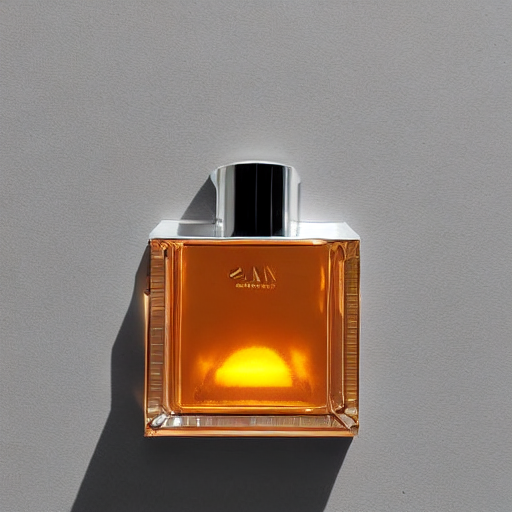

  0%|          | 0/25 [00:00<?, ?it/s]

**Image 2 — prompt:** Luxury product photograph of one rectangular clear glass perfume bottle filled with pale amber liquid, black cap, simple blank cream label, on dark marble beside rose petals and bergamot peel, warm dramatic side lighting, editorial fragrance campaign photography

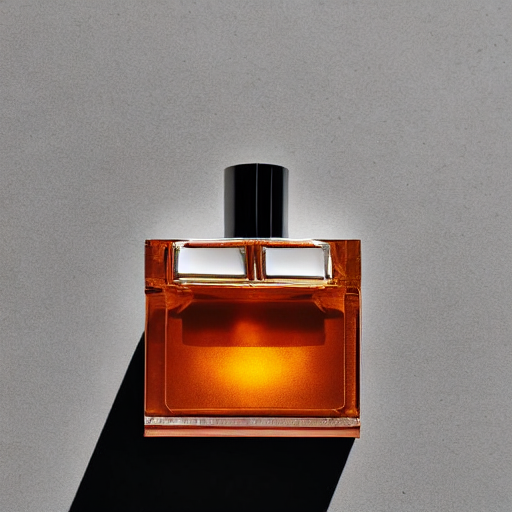

In [5]:
from diffusers import StableDiffusionPipeline
if not torch.cuda.is_available():
    raise RuntimeError('Part C requires a GPU for practical runtime. Select Runtime > Change runtime type > T4 GPU and rerun all cells.')
clear_memory()
image_prompts = [
    'Luxury product photograph of one rectangular clear glass perfume bottle filled with pale amber liquid, black cap, simple blank cream label, centered on a white studio background, soft even lighting, front view, premium catalog photography',
    'Luxury product photograph of one rectangular clear glass perfume bottle filled with pale amber liquid, black cap, simple blank cream label, on dark marble beside rose petals and bergamot peel, warm dramatic side lighting, editorial fragrance campaign photography'
]
pipe = StableDiffusionPipeline.from_pretrained(
    'stable-diffusion-v1-5/stable-diffusion-v1-5', dtype=torch.float16, use_safetensors=True)
pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()
# Removed pipe.enable_vae_slicing() as it is not supported in this diffusers version
images = []
for index, prompt in enumerate(image_prompts, 1):
    result_c = pipe(prompt, negative_prompt='blurry, distorted bottle, duplicate bottles, watermark, illegible text',
                    height=512, width=512, num_inference_steps=25, guidance_scale=7.5,
                    generator=torch.Generator(device='cpu').manual_seed(42))
    flags = result_c.nsfw_content_detected
    if flags and any(flags):
        raise RuntimeError('Safety checker flagged an image. Revise the product prompt and rerun; keep the checker enabled.')
    img = result_c.images[0]
    images.append(img)
    img.save(OUT/f'perfume_{index}.png')
    display(Markdown(f'**Image {index} — prompt:** {prompt}'))
    display(img)
del pipe, result_c
clear_memory()

### Image differences
**Background and composition:** Both images show a single amber-filled rectangular bottle against a gray background with a strong shadow extending toward the lower left. Image 1 has a wider, reflective cap and small unreadable gold markings on the bottle. Image 2 has a narrower black cylindrical cap, a more square bottle body, and two bright rectangular details near its shoulders. Neither image has the requested simple cream label.

**Lighting, color, and mood:** Both images use strong directional lighting and saturated orange-amber liquid, with bright highlights near the bottom. Image 1 appears slightly more golden; image 2 has a darker central area and a deeper orange tone. Prompt 1 did not produce the requested white background with soft even lighting. Prompt 2 did not visibly produce dark marble, rose petals, or bergamot peel. Its output remained much closer to a studio shot than the intended editorial scene.

**Business usefulness and flaws:** Image 1 is my stronger preliminary visual concept because its reflective cap and golden liquid suggest premium packaging. Image 2 could provide an alternative bottle-design concept, but it does not achieve the requested campaign setting. Neither should be used as a final catalog photo: the bottle designs differ, approved branding is absent, and the packaging does not consistently match the prompts. A designer would need to establish one real bottle specification and create or approve accurate final artwork.

For reruns, keep the safety checker enabled. If GPU memory runs out, restart and run the cells in order. Seeds improve repeatability but do not guarantee identical images across software and hardware changes.


## Part D — Evaluation and responsible AI (15 points)

### 1. Which model generated the most useful output for your business scenario, and why?
FLAN-T5 produced the most useful output for reviewing the launch decision. It correctly retained the 420-bottle pilot sales result against a 500-bottle target, USD 60,900 gross revenue, survey percentages, and the supplier and acquisition-cost risks. These are relevant management facts. Its omissions and repetition require editing, but it is more dependable for this purpose than GPT-2's invented product claims. Stable Diffusion supplied useful bottle concepts but failed to follow several visual instructions and did not keep one consistent bottle design.

### 2. How did changing the prompts affect the outputs?
The short GPT-2 prompt produced a news-style perfume announcement, whereas the detailed prompt produced more enthusiastic promotional language and unrelated references to pastries and flavor. Extra detail therefore did not improve the generated continuation in this run. For Stable Diffusion, the second prompt changed the cap and bottle details, but both results retained a gray studio background and strong shadows. The requested marble, petals, and bergamot peel were absent. Holding the seed and settings fixed helped comparison, although one pair of outputs cannot establish a general rule about prompt effectiveness.

### 3. Identify one limitation or possible error in the generated text or image.
GPT-2 invented “3-5 drops per package,” which is not supported by the product description or report. It also discussed flavor, which is inappropriate for this perfume scenario. This demonstrates that fluent generation can introduce incorrect product information. FLAN-T5 additionally omitted the marketing budget and sales goals, while Stable Diffusion failed to maintain consistent packaging between images.

### 4. Would you use these outputs directly in a real business? Explain what human review is needed.
I would use these outputs as drafts or concepts requiring approval. An analyst should compare the summary with the full report and restore missing decision facts. Marketing staff should remove invented events, ingredients, and performance claims, then check tone and suitability for the intended audience. A designer should verify bottle shape, labels, lighting, and consistency with the real product. Relevant staff should review model licenses and rights before commercial use. Customer information should not be included unnecessarily in model inputs, and synthetic concept images should be identified appropriately. People remain responsible for the published claims and final business decision.

## Part E — Conclusion (5 points)
These models supported three different tasks within the same perfume launch, but their outputs required different kinds of review. FLAN-T5 provided the strongest business starting point because it retained several important facts. My most important revision would be to restore its missing budget and targets and remove the repeated opening. The GPT-2 and Stable Diffusion comparisons also showed that more specific prompts do not guarantee accurate text or faithful images.


In [6]:
manifest = {'models': ['google/flan-t5-base', 'openai-community/gpt2', 'stable-diffusion-v1-5/stable-diffusion-v1-5'],
            'seed': 42, 'device': DEVICE, 'torch': torch.__version__,
            'transformers': transformers.__version__, 'diffusers': diffusers.__version__,
            'report': report, 'summary': summary, 'ad_prompts': prompts_b,
            'ad_continuations': ads, 'image_prompts': image_prompts}
(OUT/'run_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Generated artifacts saved in', OUT)
print('Save and download the NOTEBOOK with outputs using Colab File menu. These files alone are not the submission.')


Generated artifacts saved in /content/aurore_outputs
Save and download the NOTEBOOK with outputs using Colab File menu. These files alone are not the submission.
